# 01 - Análise Exploratória dos Dados (EDA)
**Projeto 01 - Inteligência Artificial** · Grupo **G05** - Marina Silva (31029) · Nelson Cruz (31103) · Nuno Oliveira (31550) · Ricardo Pinto (14865)

Objetivo deste notebook (slide 15 do enunciado):
- carregar os CSVs e perceber como as tabelas se ligam;
- **validar a integridade** dos dados e das **janelas de tempo**;
- comparar os **pesos com as capacidades** das carrinhas;
- **mapear as paragens**.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import glob, os
from model import load_data, load_rules, build_travel, validate_data, Problem, PRIMARY_KEYS
from search import triangle_inequality_holds

DATA_PATH = "data_tiny"      # ← outro dataset: mudar aqui
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## 1. Carregar os dados

O `load_data` do `model.py` lê os 12 CSVs para um **dicionário de DataFrames** e converte as 4 colunas de datas dos `order_items`.

In [2]:
data = load_data(DATA_PATH)
# Quantidade de registos de CADA ficheiro, em todos os datasets da pasta (lado a lado)
datasets = {os.path.basename(p): load_data(p) for p in sorted(glob.glob("data_*"))}
pd.DataFrame({name: {f: len(df) for f, df in d.items()} for name, d in datasets.items()}).rename_axis("ficheiro")

,data_small,data_tiny
ficheiro,,
collection_centers,1,1
customers,21,12
delivery_locations,7,5
distance_matrix,182,72
localities,49,49
locations,14,9
order_items,80,40
orders,25,12
producers,6,3


### Campos de cada ficheiro, nulos e duplicados

In [3]:
rows = []
for name, df in data.items():
    key = PRIMARY_KEYS.get(name)
    rows.append({"ficheiro": name, "registos": len(df),
                 "campos (tipo)": ", ".join(f"{c} ({t})" for c, t in df.dtypes.astype(str).items()),
                 "valores nulos": int(df.isna().sum().sum()),
                 "linhas duplicadas": int(df.duplicated().sum()),
                 "chave primária": key or "—",
                 "chaves repetidas": int(df[key].duplicated().sum()) if key else "—"})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index("ficheiro")

,registos,campos (tipo),valores nulos,linhas duplicadas,chave primária,chaves repetidas
ficheiro,,,,,,
collection_centers,1,"center_id (int64), name (str), locality_id (int64), address (str), capacity_kg (float64)",0,0,center_id,0
customers,12,"customer_id (int64), name (str), locality_id (int64), phone (str), email (str)",0,0,customer_id,0
delivery_locations,5,"delivery_location_id (int64), name (str), locality_id (int64), address (str), location_type (str)",0,0,delivery_location_id,0
distance_matrix,72,"origin_location_id (int64), origin_type (str), destination_location_id (int64), destination_type (str), distance_km ...",0,0,—,—
localities,49,"locality_id (int64), name (str), municipality (str), district (str), latitude (float64), longitude (float64)",0,0,—,—
locations,9,"location_id (int64), location_type (str), ref_id (int64), name (str), municipality (str), latitude (float64), longit...",0,0,location_id,0
order_items,40,"order_item_id (int64), order_id (int64), product_id (int64), quantity (float64), weight_kg (float64), availability_s...",0,0,order_item_id,0
orders,12,"order_id (int64), customer_id (int64), delivery_location_id (int64), order_datetime (str), status (str)",0,0,order_id,0
producers,3,"producer_id (int64), name (str), locality_id (int64), address (str), phone (str), email (str)",0,0,producer_id,0


### Como as tabelas se ligam

```
                         order_items  (peso, janelas)
                        /                          \
                (product_id)                    (order_id)
                    /                                \
              products                              orders
                  |                                    |
            (producer_id)                    (delivery_location_id)
                  |                                    |
   locations [type = producer]           locations [type = delivery_location]
     producer_id = ref_id                  delivery_location_id = ref_id
                  |                                    |
           location_id = ORIGEM               location_id = DESTINO
```

- A `distance_matrix` só conhece **`location_id`** (1 a 9). O `locations.csv` é o "tradutor" entre os ids de cada tabela (`ref_id`) e o id único do mapa (`location_id`).
- O destino de uma encomenda é o **local de entrega** escolhido, **não** a morada do cliente (ex.: o cliente da encomenda 1 mora em Esposende, mas a entrega é em Guimarães).
- `customers` e `localities` não entram nas rotas.

In [4]:
data["locations"]

,location_id,location_type,ref_id,name,municipality,latitude,longitude
0,1,producer,1,Hortas Valente,Fafe,41.474322,-8.174295
1,2,producer,2,Campos Leite,Vieira do Minho,41.633412,-8.125896
2,3,producer,3,Horta Morais,Terras de Bouro,41.716185,-8.340221
3,4,collection_center,1,Centro de Recolha 1,Braga,41.531493,-8.446483
4,5,delivery_location,1,Loja 1,Guimaraes,41.464457,-8.297740
5,6,delivery_location,2,Casa 2,Esposende,41.553679,-8.778977
6,7,delivery_location,3,Casa 3,Guimaraes,41.418772,-8.289729
7,8,delivery_location,4,Casa 4,Vila Nova de Famalicao,41.394239,-8.520320
8,9,delivery_location,5,Loja 5,Guimaraes,41.418772,-8.289729


## 2. Integridade

Verificamos que todas as chaves estrangeiras existem, que não há ids repetidos e que a matriz cobre todos os pares de sítios.

In [5]:
def check(label, condition):
    print(("✓ " if condition else "✗ ") + label)

oi, prod, orders = data["order_items"], data["products"], data["orders"]
loc, dm = data["locations"], data["distance_matrix"]

check("ids únicos em order_items", oi["order_item_id"].is_unique)
check("todos os order_items têm encomenda", oi["order_id"].isin(orders["order_id"]).all())
check("todos os order_items têm produto", oi["product_id"].isin(prod["product_id"]).all())
check("todos os produtos têm produtor", prod["producer_id"].isin(data["producers"]["producer_id"]).all())
check("todas as encomendas têm local de entrega",
      orders["delivery_location_id"].isin(data["delivery_locations"]["delivery_location_id"]).all())
check("todas as encomendas têm cliente", orders["customer_id"].isin(data["customers"]["customer_id"]).all())
check("todos os produtores estão em locations",
      set(data["producers"]["producer_id"]) == set(loc[loc.location_type == "producer"]["ref_id"]))
check("todos os locais de entrega estão em locations",
      set(data["delivery_locations"]["delivery_location_id"]) == set(loc[loc.location_type == "delivery_location"]["ref_id"]))
check("há exatamente 1 centro de recolha (armazém)", (loc.location_type == "collection_center").sum() == 1)
n = len(loc)
check(f"a matriz tem n × (n − 1) = {n} × {n - 1} = {n * (n - 1)} pares", len(dm) == n * (n - 1))
check("não há pares de um sítio para ele próprio", (dm.origin_location_id != dm.destination_location_id).all())
check("todas as encomendas estão 'confirmed'", (orders["status"] == "confirmed").all())
print("\nvalidate_data (a mesma validação que o Problem faz ao carregar):", validate_data(data) or "sem problemas")

✓ ids únicos em order_items
✓ todos os order_items têm encomenda
✓ todos os order_items têm produto
✓ todos os produtos têm produtor
✓ todas as encomendas têm local de entrega
✓ todas as encomendas têm cliente
✓ todos os produtores estão em locations
✓ todos os locais de entrega estão em locations
✓ há exatamente 1 centro de recolha (armazém)
✓ a matriz tem n × (n − 1) = 9 × 8 = 72 pares
✓ não há pares de um sítio para ele próprio
✓ todas as encomendas estão 'confirmed'

validate_data (a mesma validação que o Problem faz ao carregar): sem problemas


### Peso: `quantity` não é sempre igual a `weight_kg`

Há produtos vendidos à unidade (ovos em caixas de 1,8 kg, grelos a 0,8 kg). Para a **capacidade** usa-se sempre o `weight_kg`.

In [6]:
x = oi.merge(prod, on="product_id")
x["calc"] = x["quantity"] * x["unit_weight_kg"]
check("weight_kg = quantity × unit_weight_kg em todos os itens", np.allclose(x["calc"], x["weight_kg"]))
x[x["quantity"] != x["weight_kg"]][["order_item_id", "name", "unit", "quantity", "unit_weight_kg", "weight_kg"]]

✓ weight_kg = quantity × unit_weight_kg em todos os itens


,order_item_id,name,unit,quantity,unit_weight_kg,weight_kg
17,18,Ovos,crate,3.0,1.8,5.4
27,28,Ovos,crate,4.0,1.8,7.2
34,35,Grelos,kg,2.5,0.8,2.0


## 3. Janelas de tempo

Cada item tem duas janelas: **recolha** (`availability_*`, no produtor) e **entrega** (`delivery_*`, no destino). Convertemos tudo para **minutos desde o `start_date`** (2026-10-30 00:00) — é assim que o modelo trabalha.

In [7]:
problem = Problem(DATA_PATH)
req = problem.requests.copy()
rules = problem.rules
W = problem.warehouse_id
req["pick_day"] = (req["pick_start"] // 1440).astype(int)
req["deliv_day"] = (req["deliv_start"] // 1440).astype(int)

check("janela de recolha: início < fim", (req.pick_start < req.pick_end).all())
check("janela de entrega: início < fim", (req.deliv_start < req.deliv_end).all())
check("nenhuma janela começa antes do start_date", (req[["pick_start", "deliv_start"]] >= 0).all().all())
check("cada janela começa e acaba no mesmo dia",
      ((req.pick_end // 1440) == req.pick_day).all() and ((req.deliv_end // 1440) == req.deliv_day).all())
check("nenhum item é entregue num dia anterior ao da recolha", (req.deliv_day >= req.pick_day).all())
pd.crosstab(req["pick_day"], req["deliv_day"], rownames=["dia da recolha"], colnames=["dia da entrega"])

✓ janela de recolha: início < fim
✓ janela de entrega: início < fim
✓ nenhuma janela começa antes do start_date
✓ cada janela começa e acaba no mesmo dia
✓ nenhum item é entregue num dia anterior ao da recolha


dia da entrega,0,1
dia da recolha,,
0,14,10
1,0,16


**10 itens** são recolhidos no dia 0 (30/out) e só entregues no dia 1 (31/out): passam a noite no armazém, e é aqui que entra a regra `max_warehouse_dwell_h = 24`.

### Cada item, sozinho, é viável?

O caminho obrigatório é **produtor → armazém → destino** (`flow`). O mais cedo que um item pode chegar ao destino é: abrir a recolha + 10 min de serviço + viagem ao armazém + 15 + 15 min no armazém + viagem ao destino. Se isso passasse o fim da janela de entrega, o item seria impossível.

In [8]:
tm = problem.travel_minutes
S, H = rules["stop_service_min"], rules["warehouse_handling_min"]
req["earliest_arrival"] = (req.pick_start + S + req.origin_id.map(lambda o: tm[o][W]) + 2 * H
                           + req.destination_id.map(lambda d: tm[W][d]))
req["slack_min"] = req.deliv_end - req.earliest_arrival
check("todos os itens são viáveis sozinhos", (req.slack_min >= 0).all())
req.sort_values("slack_min")[["product_name", "origin_name", "destination_name", "pick_start",
                              "deliv_end", "earliest_arrival", "slack_min"]].head(8)

✓ todos os itens são viáveis sozinhos


,product_name,origin_name,destination_name,pick_start,deliv_end,earliest_arrival,slack_min
order_item_id,,,,,,,
21,Castanha,Hortas Valente,Loja 5,1980.0,2250.0,2092.2,157.8
2,Cereja,Hortas Valente,Casa 3,1935.0,2205.0,2047.2,157.8
13,Batata,Hortas Valente,Casa 3,540.0,825.0,652.2,172.8
20,Pera,Hortas Valente,Loja 5,1965.0,2250.0,2077.2,172.8
19,Cereja,Hortas Valente,Loja 5,1965.0,2250.0,2077.2,172.8
16,Laranja,Campos Leite,Casa 3,1935.0,2235.0,2056.6,178.4
15,Curgete,Campos Leite,Loja 1,1890.0,2190.0,2005.3,184.7
40,Batata,Hortas Valente,Casa 2,570.0,885.0,699.0,186.0


Sozinho, mesmo o item mais apertado tem mais de 2 h de folga. **A dificuldade não está em cada item: está em encaixar todos nas mesmas rotas.**

### As janelas ao longo dos dois dias

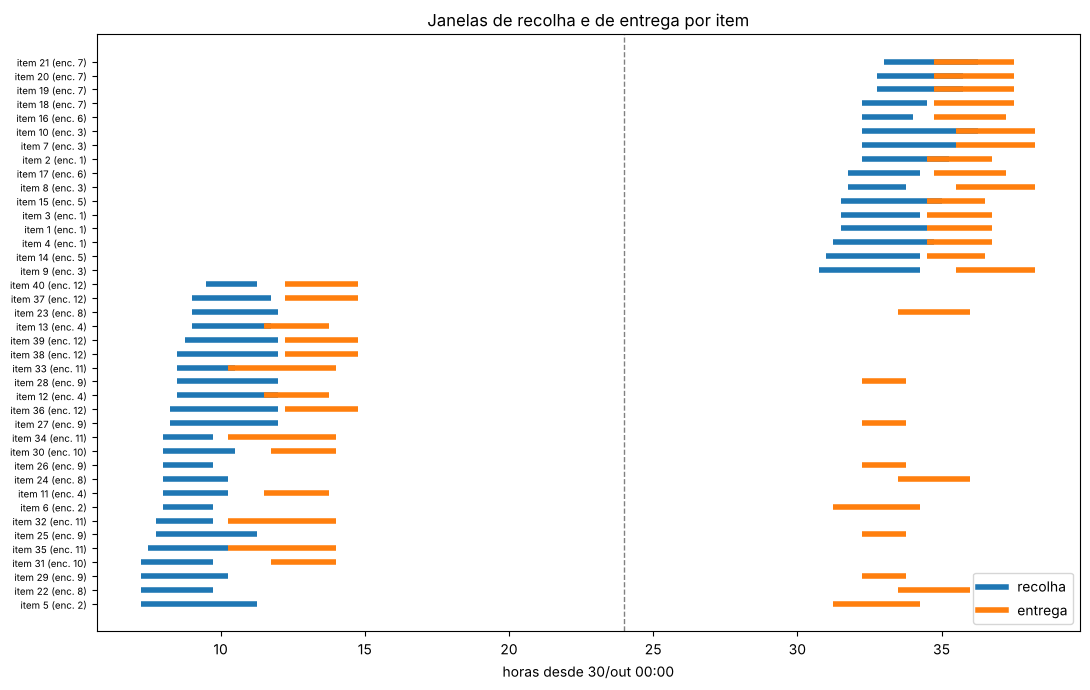

In [9]:
fig, ax = plt.subplots(figsize=(11, 7))
order = req.sort_values(["pick_day", "pick_start"]).index
for y, i in enumerate(order):
    r = req.loc[i]
    ax.plot([r.pick_start / 60, r.pick_end / 60], [y, y], color="tab:blue", lw=4, solid_capstyle="butt")
    ax.plot([r.deliv_start / 60, r.deliv_end / 60], [y, y], color="tab:orange", lw=4, solid_capstyle="butt")
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"item {i} (enc. {req.loc[i, 'order_id']})" for i in order], fontsize=7)
ax.set_xlabel("horas desde 30/out 00:00")
ax.axvline(24, color="grey", ls="--", lw=1)
ax.plot([], [], color="tab:blue", lw=4, label="recolha")
ax.plot([], [], color="tab:orange", lw=4, label="entrega")
ax.legend(loc="lower right")
ax.set_title("Janelas de recolha e de entrega por item")
plt.tight_layout()

Padrão claro: em cada dia, as **recolhas** são de manhã (≈ 07:00–12:15) e as **entregas** a meio do dia (≈ 10:15–14:45). Os itens que passam a noite são recolhidos no dia 0 e entregues **de manhã cedo** no dia 1 (07:15–12:00).

## 4. Pesos e capacidades

In [10]:
veh = data["vehicles"]
print(veh[["vehicle_id", "plate", "capacity_kg", "refrigerated"]].to_string(index=False))
print(f"\nPeso total: {req.weight_kg.sum():.1f} kg  |  capacidade das 2 carrinhas juntas: {veh.capacity_kg.sum():.0f} kg")
pd.DataFrame({
    "recolhido (kg)": req.groupby("pick_day").weight_kg.sum(),
    "entregue (kg)": req.groupby("deliv_day").weight_kg.sum(),
}).rename_axis("dia")

 vehicle_id    plate  capacity_kg  refrigerated
          1 ZG-06-DP        150.0             1
          2 TY-74-YA        200.0             0

Peso total: 270.0 kg  |  capacidade das 2 carrinhas juntas: 350 kg


,recolhido (kg),entregue (kg)
dia,,
0,166.9,104.6
1,103.1,165.4


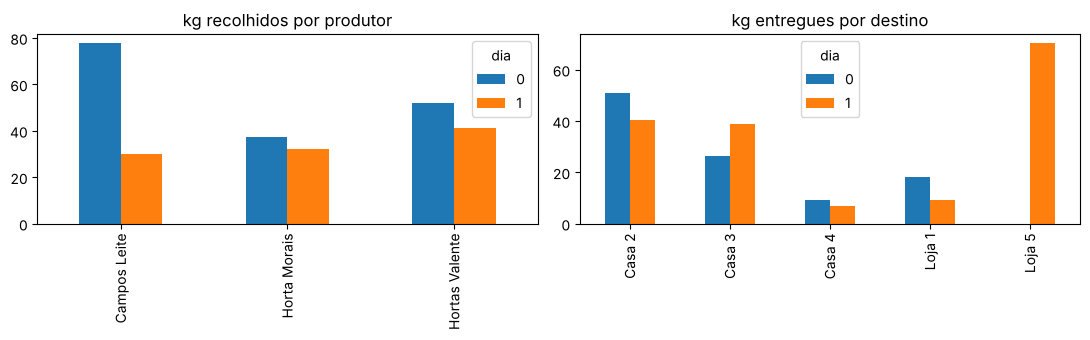

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
req.groupby(["pick_day", "origin_name"]).weight_kg.sum().unstack(0).plot.bar(ax=axes[0])
axes[0].set_title("kg recolhidos por produtor"); axes[0].set_xlabel(""); axes[0].legend(title="dia")
req.groupby(["deliv_day", "destination_name"]).weight_kg.sum().unstack(0).plot.bar(ax=axes[1])
axes[1].set_title("kg entregues por destino"); axes[1].set_xlabel(""); axes[1].legend(title="dia")
plt.tight_layout()

In [12]:
print("Produtores diferentes por encomenda:")
print(req.groupby("order_id").origin_id.nunique().value_counts().sort_index().rename("nº de encomendas").to_string())
print("\nNenhum produto indica precisar de frio:", sorted(prod["category"].unique()))

Produtores diferentes por encomenda:
origin_id
2    7
3    5

Nenhum produto indica precisar de frio: ['fruit', 'other', 'vegetable']


- A **capacidade não é o maior aperto**: nenhum dia passa os 350 kg das duas carrinhas, e mesmo a carrinha pequena (150 kg) leva quase o dia inteiro.
- Cada encomenda vem de **2 ou 3 produtores** → muitas paragens de recolha.
- A carrinha 1 é **refrigerada**, mas nenhum produto tem essa exigência: o atributo é ignorado no modelo (decisão a registar).

## 5. Matriz de distâncias

In [13]:
km, mins = build_travel(data)
d = lambda a, b: 0.0 if a == b else km[a][b]
ids = sorted(km)
check("simétrica (km e minutos)",
      all(km[a][b] == km[b][a] and mins[a][b] == mins[b][a] for a in ids for b in ids if a != b))
violations = [(a, b, c) for a in ids for b in ids for c in ids if d(a, c) > d(a, b) + d(b, c) + 1e-9]
check(f"desigualdade triangular d(a,c) ≤ d(a,b) + d(b,c)  ({len(violations)} violações)", not violations)
for name, path in [(n, p) for n, p in zip(datasets, sorted(glob.glob("data_*")))]:
    print(f"   {name}: desigualdade triangular {'cumprida' if triangle_inequality_holds(Problem(path)) else 'NÃO cumprida'}")
speed = rules["avg_speed_kmh"]
check(f"minutos = km / {speed:.0f} km/h × 60", all(abs(mins[a][b] - km[a][b] / speed * 60) < 0.1
                                                   for a in ids for b in ids if a != b))
print("\nPares a 0 km:", dm[dm.distance_km == 0][["origin_location_id", "destination_location_id"]].values.tolist())

✓ simétrica (km e minutos)
✓ desigualdade triangular d(a,c) ≤ d(a,b) + d(b,c)  (0 violações)
   data_small: desigualdade triangular NÃO cumprida
   data_tiny: desigualdade triangular cumprida
✓ minutos = km / 45 km/h × 60

Pares a 0 km: [[7, 9], [9, 7]]


- A **desigualdade triangular** é importante para a heurística H1 do A*. No *tiny* é cumprida; no *small* falha por **0,01 km** em 6 triplos (arredondamentos). Por isso a H1 usa distâncias de **caminho mais curto** (que a cumprem sempre) — ver secção 5 do notebook principal.
- Os sítios **7 e 9** (Casa 3 e Loja 5) estão a **0 km**: ficam na mesma localidade. Não é um erro, mas são paragens diferentes.

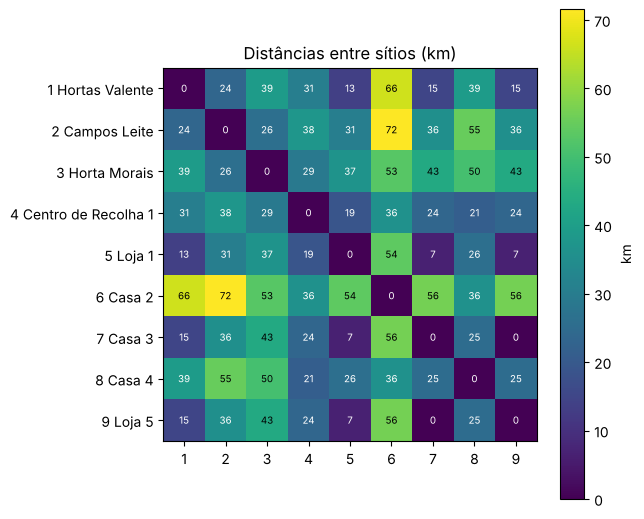

In [14]:
names = loc.set_index("location_id")["name"]
M = pd.DataFrame([[d(a, b) for b in ids] for a in ids], index=ids, columns=ids)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(M, cmap="viridis")
ax.set_xticks(range(len(ids))); ax.set_xticklabels(ids)
ax.set_yticks(range(len(ids))); ax.set_yticklabels([f"{i} {names[i]}" for i in ids])
for a in range(len(ids)):
    for b in range(len(ids)):
        ax.text(b, a, f"{M.iloc[a, b]:.0f}", ha="center", va="center", fontsize=7,
                color="white" if M.iloc[a, b] < 40 else "black")
plt.colorbar(im, label="km")
ax.set_title("Distâncias entre sítios (km)")
plt.tight_layout()

## 6. Mapa das paragens

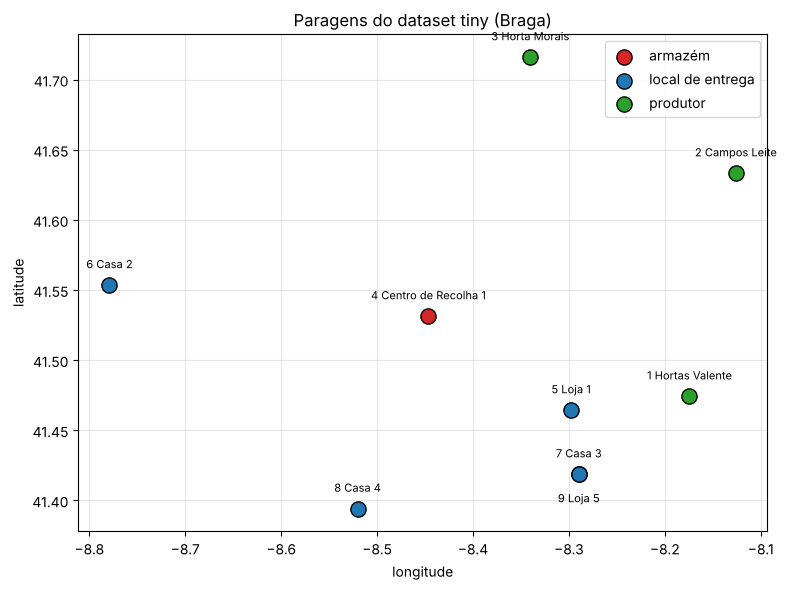

In [15]:
colors = {"producer": "tab:green", "collection_center": "tab:red", "delivery_location": "tab:blue"}
labels = {"producer": "produtor", "collection_center": "armazém", "delivery_location": "local de entrega"}
fig, ax = plt.subplots(figsize=(8, 6))
for t, g in loc.groupby("location_type"):
    ax.scatter(g.longitude, g.latitude, s=120, c=colors[t], label=labels[t], edgecolor="black", zorder=3)
for _, r in loc.iterrows():
    dy = 0.012 if r.location_id != 9 else -0.02          # 7 e 9 estão no mesmo sítio
    ax.annotate(f"{r.location_id} {r['name']}", (r.longitude, r.latitude + dy), fontsize=8, ha="center")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Paragens do dataset tiny (Braga)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()

## 7. Conclusões da EDA

1. **Os dados estão íntegros**: todas as chaves existem, não há ids repetidos e a matriz cobre os 72 pares.
2. **As janelas são coerentes**, e cada item é viável sozinho, com mais de 2 h de folga.
3. **10 itens passam a noite no armazém** → a regra das 24 h tem de ser modelada.
4. **A capacidade raramente aperta.** O que aperta é o **tempo**: muitas paragens (2–3 produtores por encomenda) e janelas de entrega curtas.
5. **O destino 6 (Casa 2, Esposende)** fica longe de tudo (≈ 48 min do armazém, > 70 min dos produtores) — é o ponto crítico das rotas.
6. **A matriz é simétrica**; a desigualdade triangular é cumprida no *tiny* mas não no *small* (0,01 km) → a H1 usa caminhos mais curtos para continuar admissível.
7. Para a capacidade usa-se o `weight_kg`; o atributo `refrigerated` é ignorado (nenhum produto precisa de frio).